In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Small change: look for the CSV in the usual places so the notebook runs from any folder
FILE_NAME = "Punjab_Fire_Data_Combined_2020_2025.csv"
DATA_PATH = next((p for p in [Path(FILE_NAME), Path("data") / FILE_NAME, Path("..") / "data" / FILE_NAME]
                  if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"{FILE_NAME} not found. Put it next to this notebook or in the project's data/ folder.")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Total rows: 295685
Total columns: 16


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,source_file
0,30.61414,73.89183,334.98,0.38,0.36,2020-08-03,808,SNPP,SNPP,n,2,301.69,2.76,D,0,fire_archive_SV-C2_833415.csv
1,30.76861,74.19826,336.06,0.38,0.36,2020-08-03,808,SNPP,SNPP,n,2,302.92,2.81,D,0,fire_archive_SV-C2_833415.csv
2,31.25200,76.92764,305.41,0.40,0.37,2020-08-03,2032,SNPP,SNPP,n,2,289.11,0.48,N,0,fire_archive_SV-C2_833415.csv
3,31.25934,76.92464,302.31,0.40,0.37,2020-08-03,2032,SNPP,SNPP,n,2,289.26,0.55,N,2,fire_archive_SV-C2_833415.csv
4,32.48193,74.31785,314.75,0.50,0.41,2020-08-03,2031,SNPP,SNPP,n,2,288.02,1.59,N,0,fire_archive_SV-C2_833415.csv


# Added section 1 — Data quality checks

Dataset: NASA FIRMS VIIRS S-NPP satellite fire detections, bounding box around Punjab, 2020–2025.
Every row is a **satellite fire detection** (thermal anomaly). A detection is *not* confirmed to be stubble burning.

In [2]:
# 1.1 Shape, column names and data types
print("Dataset shape (rows, columns):", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())

Dataset shape (rows, columns): (295685, 16)

Column names: ['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type', 'source_file']

Data types:


,dtype
latitude,float64
longitude,float64
brightness,float64
scan,float64
track,float64
acq_date,str
acq_time,int64
satellite,str
instrument,str
confidence,str


In [3]:
# 1.2 Missing values and exact duplicate rows
missing = pd.DataFrame({"missing_count": df.isna().sum(), "missing_pct": (df.isna().mean() * 100).round(3)})
print("Missing values per column:")
display(missing)
print("Total missing cells:", int(df.isna().sum().sum()))

# 'source_file' only says which download a row came from, so it is ignored when looking for duplicates
dup_all_cols = int(df.duplicated().sum())
dup_obs_cols = int(df.drop(columns=["source_file"], errors="ignore").duplicated().sum())
print("\nExact duplicate rows (all columns):", dup_all_cols)
print("Exact duplicate rows (ignoring source_file):", dup_obs_cols)

Missing values per column:


,missing_count,missing_pct
latitude,0,0.0
longitude,0,0.0
brightness,0,0.0
scan,0,0.0
track,0,0.0
acq_date,0,0.0
acq_time,0,0.0
satellite,0,0.0
instrument,0,0.0
confidence,0,0.0


Total missing cells: 0

Exact duplicate rows (all columns): 0
Exact duplicate rows (ignoring source_file): 0


In [4]:
# 1.3 Date handling, date range and numerical summary
# Convert text dates to real dates. Rows with an unreadable date would become NaT and be reported (none are expected).
df["acq_date"] = pd.to_datetime(df["acq_date"], errors="coerce")
print("Rows with an invalid date:", int(df["acq_date"].isna().sum()))

print("\nDate range:", df["acq_date"].min().date(), "to", df["acq_date"].max().date())
print("Observation window per year (first and last detection date):")
display(df.groupby(df["acq_date"].dt.year)["acq_date"].agg(first="min", last="max", detections="size"))

# Helper columns used by the graphs below
df["year"] = df["acq_date"].dt.year
df["month"] = df["acq_date"].dt.month
df["month_name"] = df["acq_date"].dt.strftime("%b")
df["confidence_label"] = df["confidence"].map({"l": "Low", "n": "Nominal", "h": "High"}).fillna("Unknown")

print("\nNumerical summary statistics:")
display(df.select_dtypes(include="number").drop(columns=["year", "month"]).describe().T.round(3))

Rows with an invalid date: 0

Date range: 2020-08-03 to 2025-12-30
Observation window per year (first and last detection date):


,first,last,detections
acq_date,,,
2020,2020-08-03,2020-12-31,86367
2021,2021-08-01,2021-12-31,93039
2022,2022-08-12,2022-12-31,54237
2023,2023-08-01,2023-12-31,37114
2024,2024-08-02,2024-12-29,15919
2025,2025-08-02,2025-12-30,9009



Numerical summary statistics:


,count,mean,std,min,25%,50%,75%,max
latitude,295685.0,30.641,0.631,29.50,30.192,30.533,30.992,32.55
longitude,295685.0,75.229,0.691,73.85,74.704,75.208,75.725,76.95
brightness,295685.0,338.871,9.389,208.00,333.260,337.050,342.680,367.00
scan,295685.0,0.453,0.082,0.32,0.390,0.430,0.500,0.80
track,295685.0,0.471,0.110,0.36,0.380,0.440,0.550,0.78
acq_time,295685.0,812.586,159.245,653.00,749.000,809.000,833.000,2158.00
version,295685.0,2.000,0.000,2.00,2.000,2.000,2.000,2.00
bright_t31,295685.0,301.108,4.444,258.12,299.140,301.450,303.570,357.50
frp,295685.0,6.839,6.824,0.14,3.140,4.830,7.970,296.83
type,295685.0,0.012,0.158,0.00,0.000,0.000,0.000,3.00


**Reading the quality check.** The archive only contains **August–December** of each year, so every year is a partial (autumn) record rather than a full calendar year.
Counts are therefore comparable season to season, but they are not annual totals.

# Added section 2 — Exploratory data analysis graphs

All graphs use the columns that exist in the file. `confidence` is the satellite detection-confidence class
(l = low, n = nominal, h = high), not a probability.

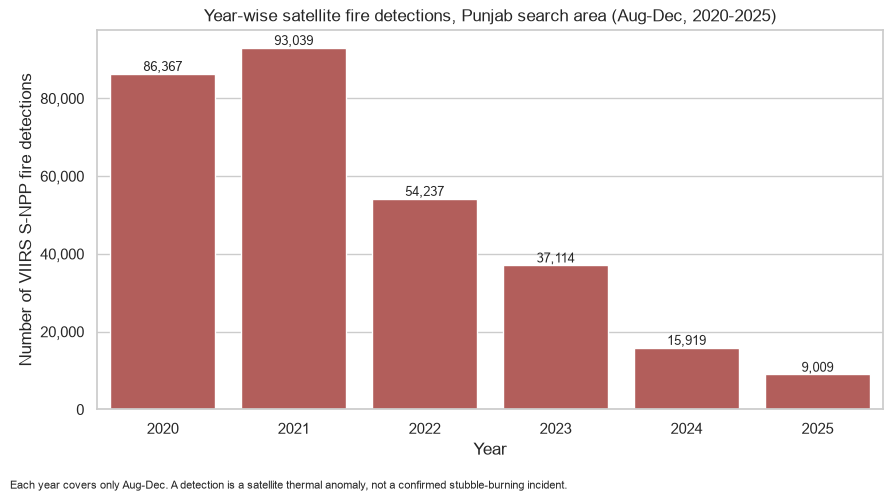

In [5]:
# Graph 1: year-wise satellite fire detections (2020-2025)
FIG_DIR = Path("figures") if Path("figures").exists() or Path("data").exists() else Path("..") / "figures"
FIG_DIR.mkdir(exist_ok=True)

yearly = df.groupby("year").size().rename("detections").reset_index()
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=yearly, x="year", y="detections", color="#c0504d", ax=ax)
for i, v in enumerate(yearly["detections"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Year-wise satellite fire detections, Punjab search area (Aug-Dec, 2020-2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Number of VIIRS S-NPP fire detections")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
fig.text(0.01, 0.005, "Each year covers only Aug-Dec. A detection is a satellite thermal anomaly, not a confirmed stubble-burning incident.", fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "01_yearly_trend.png", dpi=150)
plt.show()

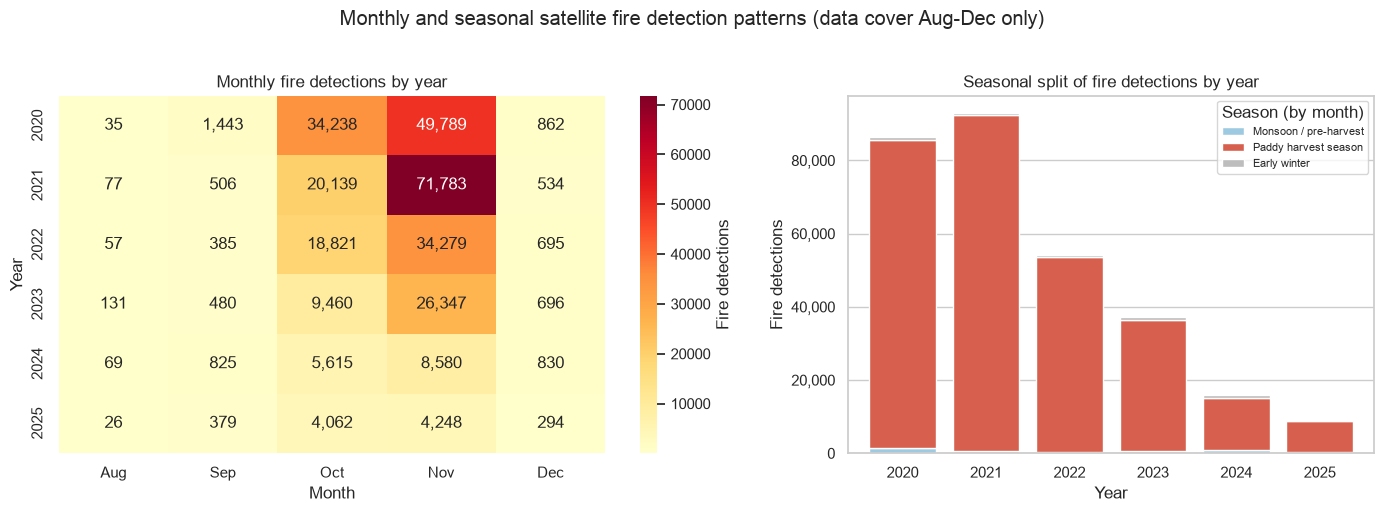

In [6]:
# Graph 2: monthly and seasonal patterns
season_map = {8: "Monsoon / pre-harvest", 9: "Monsoon / pre-harvest",
              10: "Paddy harvest season", 11: "Paddy harvest season", 12: "Early winter"}
season_order = ["Monsoon / pre-harvest", "Paddy harvest season", "Early winter"]
df["season"] = df["month"].map(season_map)

month_order = [m for m in [8, 9, 10, 11, 12] if m in df["month"].unique()]
month_labels = [pd.Timestamp(2000, m, 1).strftime("%b") for m in month_order]
pivot = df.pivot_table(index="year", columns="month", values="latitude", aggfunc="size", fill_value=0)[month_order]
pivot.columns = month_labels

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(pivot, annot=True, fmt=",d", cmap="YlOrRd", cbar_kws={"label": "Fire detections"}, ax=axes[0])
axes[0].set_title("Monthly fire detections by year")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Year")

season_counts = df.groupby(["year", "season"]).size().unstack(fill_value=0)[season_order]
season_counts.plot(kind="bar", stacked=True, ax=axes[1], color=["#9ecae1", "#d6604d", "#bdbdbd"], width=0.8)
axes[1].set_title("Seasonal split of fire detections by year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Fire detections")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="x", visible=False)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
axes[1].legend(title="Season (by month)", fontsize=8)
fig.suptitle("Monthly and seasonal satellite fire detection patterns (data cover Aug-Dec only)", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_monthly_seasonal.png", dpi=150, bbox_inches="tight")
plt.show()

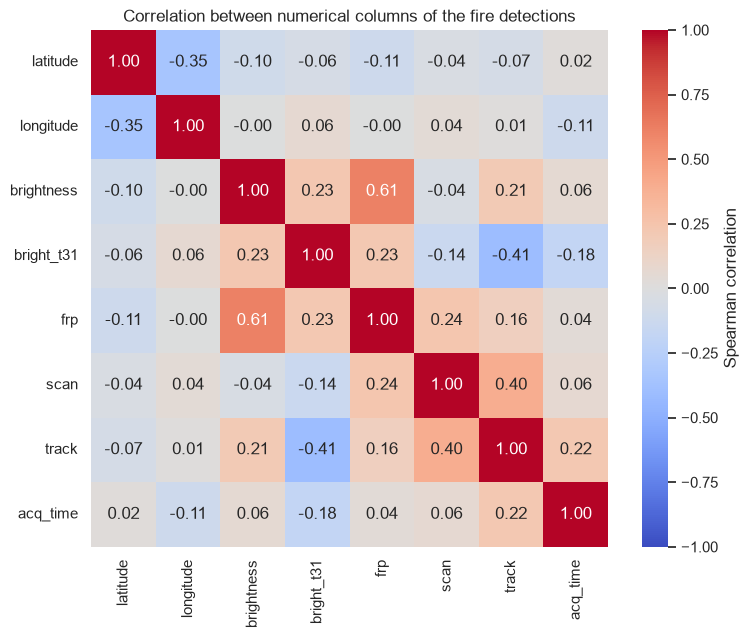

In [7]:
# Graph 3: correlation heatmap (Spearman, because brightness/FRP are skewed)
# Constant columns (version) and identifiers are excluded; only physically meaningful numeric columns are used.
corr_cols = ["latitude", "longitude", "brightness", "bright_t31", "frp", "scan", "track", "acq_time"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Correlation between numerical columns of the fire detections")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_correlation_heatmap.png", dpi=150)
plt.show()

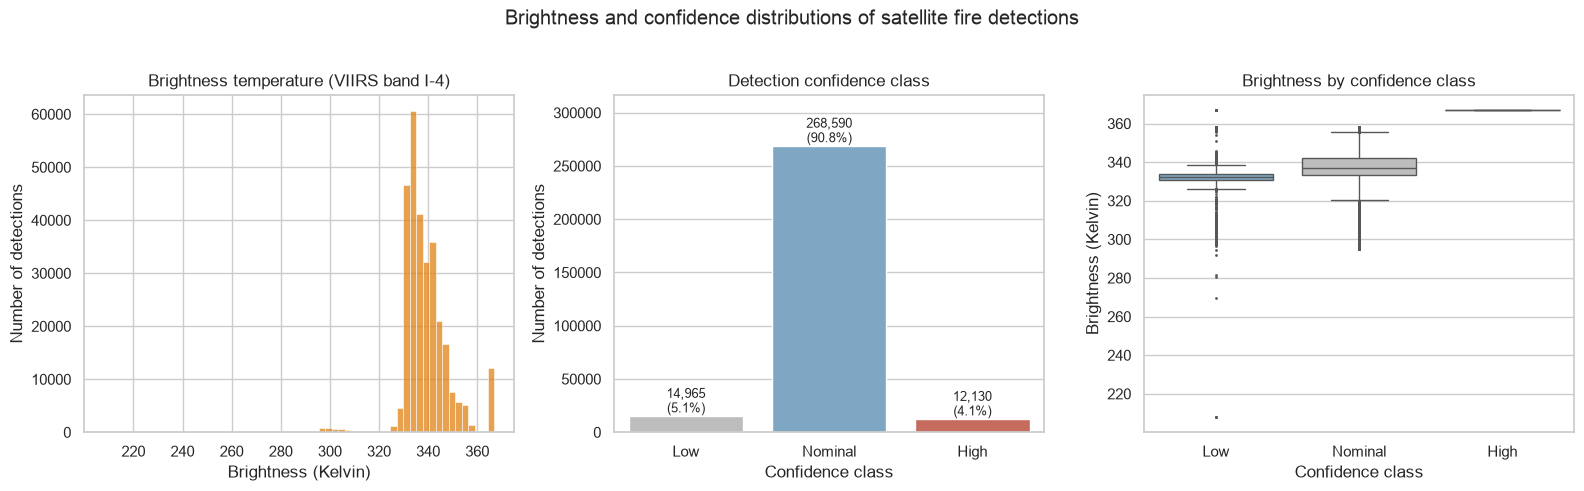

In [8]:
# Graph 4: brightness and confidence distributions
# (High-confidence detections all sit at the sensor's maximum brightness value - see the note after this cell)
conf_order = ["Low", "Nominal", "High"]
conf_counts = df["confidence_label"].value_counts().reindex(conf_order).fillna(0).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.histplot(df["brightness"], bins=60, color="#e08214", ax=axes[0])
axes[0].set_title("Brightness temperature (VIIRS band I-4)")
axes[0].set_xlabel("Brightness (Kelvin)")
axes[0].set_ylabel("Number of detections")

sns.barplot(x=conf_counts.index, y=conf_counts.values, hue=conf_counts.index, palette=["#bdbdbd", "#74a9cf", "#d6604d"],
            legend=False, ax=axes[1])
for i, v in enumerate(conf_counts.values):
    axes[1].text(i, v, f"{v:,}\n({100 * v / len(df):.1f}%)", ha="center", va="bottom", fontsize=9)
axes[1].set_title("Detection confidence class")
axes[1].set_xlabel("Confidence class")
axes[1].set_ylabel("Number of detections")
axes[1].set_ylim(0, conf_counts.max() * 1.18)

sns.boxplot(data=df, x="confidence_label", y="brightness", order=conf_order, hue="confidence_label",
            palette=["#bdbdbd", "#74a9cf", "#d6604d"], legend=False, fliersize=1, ax=axes[2])
axes[2].set_title("Brightness by confidence class")
axes[2].set_xlabel("Confidence class")
axes[2].set_ylabel("Brightness (Kelvin)")
fig.suptitle("Brightness and confidence distributions of satellite fire detections", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_brightness_confidence.png", dpi=150, bbox_inches="tight")
plt.show()

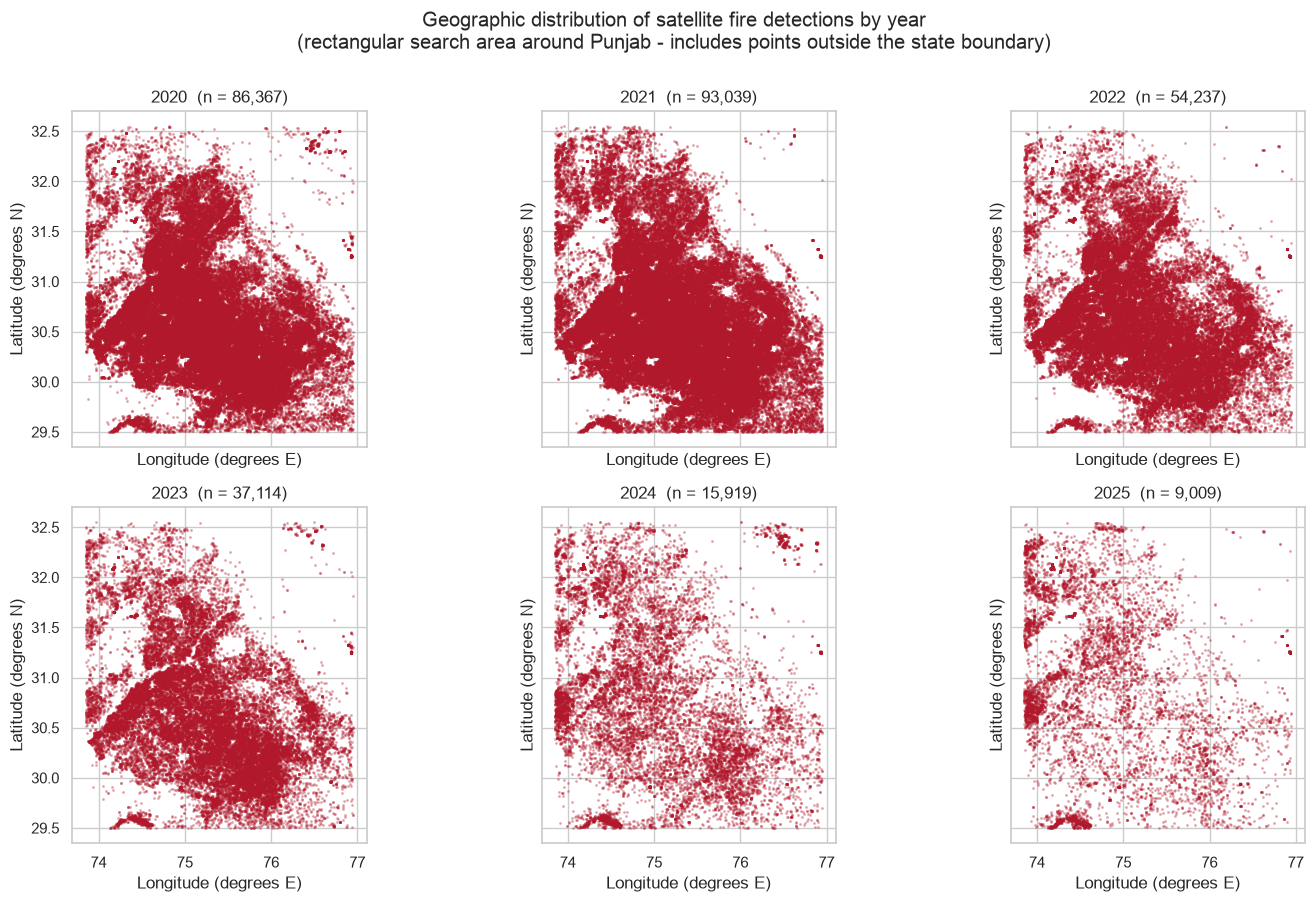

In [9]:
# Graph 5: geographic scatter of detections (latitude / longitude), one panel per year
geo = df.dropna(subset=["latitude", "longitude"])
years = sorted(geo["year"].unique())
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for ax, y in zip(axes.ravel(), years):
    d = geo[geo["year"] == y]
    ax.scatter(d["longitude"], d["latitude"], s=1.5, alpha=0.25, color="#b2182b", rasterized=True)
    ax.set_title(f"{y}  (n = {len(d):,})")
    ax.set_xlabel("Longitude (degrees E)")
    ax.set_ylabel("Latitude (degrees N)")
    ax.set_aspect(1 / np.cos(np.radians(geo["latitude"].mean())))   # keep distances roughly true
fig.suptitle("Geographic distribution of satellite fire detections by year\n"
             "(rectangular search area around Punjab - includes points outside the state boundary)", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_geographic_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

**Note on Graph 4.** The VIIRS I-4 brightness value tops out near 367 K (sensor saturation). In this file the *High*-confidence detections all share that maximum value, so their box collapses to a line and the histogram has a spike at the right edge. This reflects how the data are recorded, not a plotting error.

# Added section 3 — Weekly prediction and actual vs predicted graph

**Target:** number of satellite fire detections per week (statewide search area). It is *not* a count of confirmed stubble-burning incidents.

**Rows used:** `type == 0` (presumed vegetation fire) and confidence not `low`; the same documented filter as the main pipeline.

**Why weeks are built per season:** the data only cover Aug–Dec, so there is no information between seasons. Weeks are counted from the
first to the last week of each season (a week without detections inside that window is a true zero), and no zeros are invented for the Jan–Jul gap.

**Features (all from earlier weeks only):** counts 1, 2 and 3 weeks earlier, mean of the previous 3 weeks, and week of year.
**Evaluation:** chronological. Train on 2020–2023, test on 2024–2025. No random shuffling.

In [10]:
# Build the weekly series (filter, weekly counts, lag features) - uses only past information for each row
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

base = df[(df["type"] == 0) & (df["confidence"].str.lower() != "l")].dropna(subset=["acq_date"]).copy()
print(f"Rows used for the weekly series: {len(base):,} of {len(df):,}")

base["week_start"] = base["acq_date"].dt.to_period("W-SUN").dt.start_time   # Monday of each week
weekly = base.groupby("week_start").size().rename("fires")

pieces = []
for y, s in weekly.groupby(weekly.index.year):
    s = s.copy()
    # a season's first and last week are partial (data start/stop mid-week); keep them out of the weekly table
    full = pd.date_range(s.index.min(), s.index.max(), freq="W-MON")
    s = s.reindex(full, fill_value=0).iloc[1:-1]          # zeros only inside the observed season
    pieces.append(s)
wk = pd.concat(pieces).rename("fires").to_frame()
wk.index.name = "week_start"
wk["season_year"] = wk.index.year

g = wk.groupby("season_year")["fires"]
for k in (1, 2, 3):
    wk[f"lag{k}"] = g.shift(k)                              # shift within the same season only
wk["roll3_prev"] = g.transform(lambda s: s.shift(1).rolling(3).mean())
wk["week_of_year"] = wk.index.isocalendar().week.astype(int).values
wk = wk.dropna()                                            # first 3 weeks of each season have no full history

FEATURES = ["lag1", "lag2", "lag3", "roll3_prev", "week_of_year"]
train = wk[wk["season_year"] <= 2023]
test = wk[wk["season_year"] >= 2024]
print(f"Weekly rows: {len(wk)}  |  train {train.index.min().date()} to {train.index.max().date()} ({len(train)} weeks)"
      f"  |  test {test.index.min().date()} to {test.index.max().date()} ({len(test)} weeks)")
display(wk.head())

Rows used for the weekly series: 278,879 of 295,685
Weekly rows: 102  |  train 2020-08-31 to 2023-12-18 (68 weeks)  |  test 2024-08-26 to 2025-12-22 (34 weeks)


,fires,season_year,lag1,lag2,lag3,roll3_prev,week_of_year
week_start,,,,,,,
2020-08-31,8,2020,5.0,2.0,6.0,4.333333,36
2020-09-07,29,2020,8.0,5.0,2.0,5.000000,37
2020-09-14,196,2020,29.0,8.0,5.0,14.000000,38
2020-09-21,718,2020,196.0,29.0,8.0,77.666667,39
2020-09-28,1153,2020,718.0,196.0,29.0,314.333333,40


In [11]:
# Train the models (fixed seed) on log(1 + count) so that big and small weeks are treated on a comparable scale,
# then convert predictions back to real counts. The baseline "same as last week" is the simplest honest comparison.
SEED = 42
def to_log(X):
    X = X.copy()
    for c in ["lag1", "lag2", "lag3", "roll3_prev"]:
        X[c] = np.log1p(X[c])
    return X

models = {
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
}
preds, rows = {}, []
y_test = test["fires"]
preds["Last-week baseline"] = test["lag1"].values
for name, m in models.items():
    m.fit(to_log(train[FEATURES]), np.log1p(train["fires"]))
    preds[name] = np.clip(np.expm1(m.predict(to_log(test[FEATURES]))), 0, None)

for name, p in preds.items():
    rows.append({"model": name, "MAE": mean_absolute_error(y_test, p),
                 "RMSE": np.sqrt(mean_squared_error(y_test, p)), "R2": r2_score(y_test, p)})
results = pd.DataFrame(rows).round(3).set_index("model")
print("Held-out test results (2024-2025 weekly satellite fire detections):")
display(results)
results.to_csv(FIG_DIR / "weekly_model_metrics.csv")

Held-out test results (2024-2025 weekly satellite fire detections):


,MAE,RMSE,R2
model,,,
Last-week baseline,312.382,550.626,0.486
Ridge Regression,284.157,486.136,0.600
Random Forest,331.916,514.090,0.552


Model with the lowest test MAE: Ridge Regression


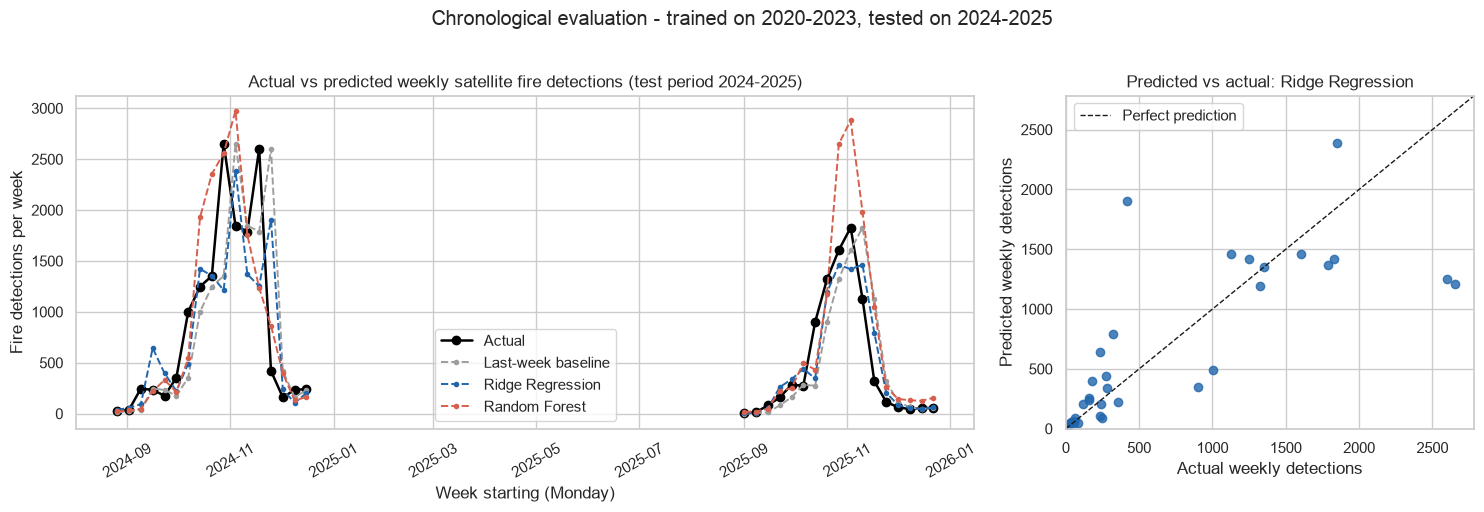

In [12]:
# Graph 6: actual vs predicted weekly satellite fire detections (test years only, chronological hold-out)
best = results["MAE"].idxmin()
print("Model with the lowest test MAE:", best)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
# one line segment per season so nothing is drawn across the Jan-Jul gap, where there is no data
colours = {"Last-week baseline": "#9e9e9e", "Ridge Regression": "#2166ac", "Random Forest": "#d6604d"}
for i, (yr, idx) in enumerate(test.groupby("season_year").groups.items()):
    mask = test.index.isin(idx)
    ax.plot(test.index[mask], y_test.values[mask], "o-", color="black", lw=1.8, label="Actual" if i == 0 else None)
    for name in preds:
        ax.plot(test.index[mask], preds[name][mask], "--", marker=".", color=colours[name], lw=1.4,
                label=name if i == 0 else None)
ax.set_title("Actual vs predicted weekly satellite fire detections (test period 2024-2025)")
ax.set_xlabel("Week starting (Monday)")
ax.set_ylabel("Fire detections per week")
ax.legend()
ax.tick_params(axis="x", rotation=30)

ax = axes[1]
ax.scatter(y_test, preds[best], color="#2166ac", alpha=0.8)
lim = max(y_test.max(), np.max(preds[best])) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, label="Perfect prediction")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title(f"Predicted vs actual: {best}")
ax.set_xlabel("Actual weekly detections")
ax.set_ylabel("Predicted weekly detections")
ax.legend()
fig.suptitle("Chronological evaluation - trained on 2020-2023, tested on 2024-2025", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_actual_vs_predicted_weekly.png", dpi=150, bbox_inches="tight")
plt.show()

**Notes and limits.** Only about 40 weekly rows are held out, so the scores are indicative, not precise.
Detections fall sharply from 2020 to 2025, so the test years are much quieter than the training years; this is a distribution shift,
and the data alone cannot say whether it reflects less burning, changes in satellite observation, or both.
The models forecast **satellite fire detections**, not confirmed stubble-burning incidents.